# Home Credit : scoring du risque de défaut de crédit
## Notebook 04 : historique des clients chez Home Credit, en SQL

Le notebook 03 a exploité les crédits contractés **ailleurs**. Celui-ci exploite l'historique des clients **chez Home Credit** : leurs demandes passées et la façon dont ils ont remboursé.

| Table | Une ligne par… | Lignes | Contenu |
|---|---|---|---|
| `previous_application` | demande antérieure | 1,7 million | montant demandé et accordé, décision (acceptée, refusée, annulée), motif de refus |
| `installments_payments` | paiement d'une échéance | 13,6 millions | date et montant prévus, date et montant réellement payés |
| `POS_CASH_balance` | crédit et par mois | 10 millions | suivi mensuel des prêts à la consommation et des prêts personnels : échéances restantes, jours de retard |
| `credit_card_balance` | carte et par mois | 3,8 millions | solde, plafond, retraits, paiements, retards |

```
installments_payments ─┐
POS_CASH_balance ──────┼──(agrégées par crédit : SK_ID_PREV, puis par client : SK_ID_CURR)──► application
credit_card_balance ───┤
previous_application ──┘
```

On termine en mesurant, table par table, **ce que chaque source d'information apporte** à la régression logistique de référence.

In [1]:
import sys
import time
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path("..").resolve()))
from src.preparation import EncodeurWoE, VARIABLES_EQUITE
from src.modelisation import pipeline_logistique, evaluer

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DOSSIER_BRUTES = Path("../data/brutes")
DOSSIER_TRAITEES = Path("../data/traitees")

con = duckdb.connect()


def sql(requete):
    """Exécute une requête SQL et renvoie le résultat sous forme de DataFrame."""
    return con.sql(requete).df()


def charger(table):
    chemin = (DOSSIER_BRUTES / f"{table}.csv").as_posix()
    con.execute(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM read_csv_auto('{chemin}')")


debut = time.time()
for table in ["previous_application", "installments_payments", "POS_CASH_balance", "credit_card_balance"]:
    charger(table)
con.execute(f"CREATE TABLE application AS SELECT * FROM '{(DOSSIER_TRAITEES / 'application_propre.parquet').as_posix()}'")
print(f"Chargement en {time.time() - debut:.1f} s")

sql("""
SELECT 'previous_application' AS table_, COUNT(*) AS lignes, COUNT(DISTINCT SK_ID_CURR) AS clients, COUNT(DISTINCT SK_ID_PREV) AS credits FROM previous_application
UNION ALL SELECT 'installments_payments', COUNT(*), COUNT(DISTINCT SK_ID_CURR), COUNT(DISTINCT SK_ID_PREV) FROM installments_payments
UNION ALL SELECT 'POS_CASH_balance',      COUNT(*), COUNT(DISTINCT SK_ID_CURR), COUNT(DISTINCT SK_ID_PREV) FROM POS_CASH_balance
UNION ALL SELECT 'credit_card_balance',   COUNT(*), COUNT(DISTINCT SK_ID_CURR), COUNT(DISTINCT SK_ID_PREV) FROM credit_card_balance
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Chargement en 13.8 s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,table_,lignes,clients,credits
0,previous_application,1670214,338857,1670214
1,installments_payments,13605401,339587,997752
2,POS_CASH_balance,10001358,337252,936325
3,credit_card_balance,3840312,103558,104307


# 1. Les demandes antérieures (`previous_application`)

## 1.1 Exploration

In [2]:
sql("""
SELECT NAME_CONTRACT_STATUS AS decision, COUNT(*) AS demandes,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM previous_application GROUP BY 1 ORDER BY demandes DESC
""")

,decision,demandes,pct
0,Approved,1036781,62.1
1,Canceled,316319,18.9
2,Refused,290678,17.4
3,Unused offer,26436,1.6


In [3]:
sql("""
SELECT CODE_REJECT_REASON AS motif_refus, COUNT(*) AS refus,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM previous_application WHERE NAME_CONTRACT_STATUS = 'Refused'
GROUP BY 1 ORDER BY refus DESC
""")

,motif_refus,refus,pct
0,HC,175231,60.3
1,LIMIT,55680,19.2
2,SCO,37467,12.9
3,SCOFR,12811,4.4
4,XNA,5236,1.8
5,VERIF,3535,1.2
6,SYSTEM,717,0.2
7,XAP,1,0.0


Les motifs de refus sont codés (le dictionnaire ne les détaille pas) : `HC` est de loin le plus fréquent, suivi de `LIMIT` (plafond) et `SCO` (score insuffisant).

Les colonnes de dates contiennent le même code 365 243 que `DAYS_EMPLOYED` dans la table principale.

In [4]:
sql("""
SELECT
    COUNT(*) FILTER (WHERE DAYS_FIRST_DRAWING = 365243) AS premier_tirage,
    COUNT(*) FILTER (WHERE DAYS_FIRST_DUE = 365243)     AS premiere_echeance,
    COUNT(*) FILTER (WHERE DAYS_LAST_DUE = 365243)      AS derniere_echeance,
    COUNT(*) FILTER (WHERE DAYS_TERMINATION = 365243)   AS fin_du_credit,
    COUNT(*)                                            AS total
FROM previous_application
""")

,premier_tirage,premiere_echeance,derniere_echeance,fin_du_credit,total
0,934444,40645,211221,225913,1670214


**Lecture.** Sur 1,7 million de demandes passées, 62 % ont été acceptées, 17 % refusées et 19 % annulées par le client. Le code 365 243 est massif pour la date du premier tirage (934 000 demandes) : il concerne surtout les demandes refusées ou annulées, pour lesquelles aucun argent n'a jamais été versé. Il est aussi fréquent pour la date de fin (226 000), qui correspond alors à des crédits encore en cours. Dans les deux cas, le code est remplacé par une valeur manquante.

## 1.2 Taux de défaut selon l'historique de demandes

In [5]:
sql("""
WITH par_client AS (
    SELECT SK_ID_CURR,
           COUNT(*) FILTER (WHERE NAME_CONTRACT_STATUS = 'Refused') AS refus
    FROM previous_application GROUP BY 1
)
SELECT CASE WHEN p.SK_ID_CURR IS NULL THEN 'aucune demande antérieure'
            WHEN p.refus = 0 THEN '0 refus'
            WHEN p.refus = 1 THEN '1 refus'
            WHEN p.refus <= 3 THEN '2-3 refus'
            ELSE '4 refus ou plus' END              AS historique,
       COUNT(*)                                     AS clients,
       ROUND(100 * AVG(a.TARGET), 2)                AS taux_defaut_pct
FROM application a
LEFT JOIN par_client p USING (SK_ID_CURR)
WHERE a.echantillon = 'apprentissage'
GROUP BY 1 ORDER BY taux_defaut_pct
""")

,historique,clients,taux_defaut_pct
0,aucune demande antérieure,13174,6.00
1,0 refus,152500,7.06
2,1 refus,37288,8.88
3,2-3 refus,27652,10.62
4,4 refus ou plus,15394,13.37


**Lecture.** Le lien est très net et **monotone** : le taux de défaut passe de 7,1 % pour les clients jamais refusés à 13,4 % pour ceux qui ont essuyé quatre refus ou plus. Home Credit a donc déjà, dans ses propres décisions passées, une information précieuse sur le risque.

Les clients **sans aucune demande antérieure** font moins souvent défaut (6,0 %). C'est l'inverse du bureau de crédit, où l'absence d'historique signalait un risque plus élevé. Une hypothèse : un nouveau client qui arrive pour la première fois n'est pas dans la même situation qu'un client qui revient régulièrement demander des crédits.

## 1.3 Agrégation par client

Une **fonction de fenêtre** isole la décision la plus récente de chaque client, et le code 365 243 est remplacé par une valeur manquante.

In [6]:
debut = time.time()
con.execute("""
CREATE OR REPLACE TABLE prev_par_client AS
WITH demandes AS (
    SELECT *,
           NULLIF(DAYS_LAST_DUE_1ST_VERSION, 365243) AS fin_prevue
    FROM previous_application
),
derniere AS (
    SELECT SK_ID_CURR, NAME_CONTRACT_STATUS AS PREV_DERNIERE_DECISION
    FROM demandes
    QUALIFY ROW_NUMBER() OVER (PARTITION BY SK_ID_CURR ORDER BY DAYS_DECISION DESC, SK_ID_PREV DESC) = 1
)
SELECT
    d.SK_ID_CURR,
    COUNT(*)                                                               AS PREV_NB_DEMANDES,
    COUNT(*) FILTER (WHERE NAME_CONTRACT_STATUS = 'Approved')              AS PREV_NB_ACCEPTEES,
    COUNT(*) FILTER (WHERE NAME_CONTRACT_STATUS = 'Refused')               AS PREV_NB_REFUSEES,
    COUNT(*) FILTER (WHERE NAME_CONTRACT_STATUS = 'Canceled')              AS PREV_NB_ANNULEES,
    AVG(CASE WHEN NAME_CONTRACT_STATUS = 'Refused' THEN 1.0 ELSE 0.0 END)  AS PREV_TAUX_REFUS,
    COUNT(*) FILTER (WHERE CODE_REJECT_REASON = 'SCO')                     AS PREV_NB_REFUS_SCORE,
    COUNT(*) FILTER (WHERE DAYS_DECISION >= -365)                          AS PREV_NB_DEMANDES_12M,
    -MAX(DAYS_DECISION)                                                    AS PREV_JOURS_DERNIERE_DEMANDE,
    -MAX(DAYS_DECISION) FILTER (WHERE NAME_CONTRACT_STATUS = 'Refused')    AS PREV_JOURS_DERNIER_REFUS,
    AVG(AMT_CREDIT / NULLIF(AMT_APPLICATION, 0)) FILTER (WHERE NAME_CONTRACT_STATUS = 'Approved')
                                                                           AS PREV_RATIO_ACCORDE_DEMANDE,
    AVG(AMT_CREDIT) FILTER (WHERE NAME_CONTRACT_STATUS = 'Approved')       AS PREV_MONTANT_MOYEN,
    AVG(RATE_DOWN_PAYMENT)                                                 AS PREV_TAUX_APPORT_MOYEN,
    AVG(CNT_PAYMENT) FILTER (WHERE NAME_CONTRACT_STATUS = 'Approved')      AS PREV_DUREE_MOYENNE,
    AVG(CASE WHEN NAME_YIELD_GROUP = 'high' THEN 1.0 ELSE 0.0 END)
        FILTER (WHERE NAME_CONTRACT_STATUS = 'Approved')                   AS PREV_PART_TAUX_ELEVE,
    COUNT(*) FILTER (WHERE NAME_CONTRACT_STATUS = 'Approved' AND fin_prevue > 0)
                                                                           AS PREV_NB_EN_COURS,
    ANY_VALUE(l.PREV_DERNIERE_DECISION)                                    AS PREV_DERNIERE_DECISION
FROM demandes d
JOIN derniere l USING (SK_ID_CURR)
GROUP BY d.SK_ID_CURR
""")
print(f"Agrégation en {time.time() - debut:.1f} s")
sql("SELECT * FROM prev_par_client LIMIT 3")

Agrégation en 2.0 s


,SK_ID_CURR,PREV_NB_DEMANDES,PREV_NB_ACCEPTEES,PREV_NB_REFUSEES,PREV_NB_ANNULEES,PREV_TAUX_REFUS,PREV_NB_REFUS_SCORE,PREV_NB_DEMANDES_12M,PREV_JOURS_DERNIERE_DEMANDE,PREV_JOURS_DERNIER_REFUS,PREV_RATIO_ACCORDE_DEMANDE,PREV_MONTANT_MOYEN,PREV_TAUX_APPORT_MOYEN,PREV_DUREE_MOYENNE,PREV_PART_TAUX_ELEVE,PREV_NB_EN_COURS,PREV_DERNIERE_DECISION
0,110103,4,4,0,0,0.000000,0,0,964,<NA>,1.092759,413512.875,0.205897,27.000000,0.000000,1,Approved
1,282962,11,4,1,6,0.090909,0,5,294,551,1.092730,682924.500,0.000000,27.000000,0.000000,2,Canceled
2,119745,13,6,5,1,0.384615,1,6,29,29,1.025541,221456.250,0.060066,10.333333,0.166667,1,Canceled


# 2. Les remboursements (`installments_payments`)

C'est la table la plus riche : pour chaque échéance d'un ancien crédit, on connaît la date et le montant **prévus** et la date et le montant **réellement payés**. Une même échéance peut être payée en plusieurs fois : on regroupe d'abord les paiements par échéance, puis par client.

Variables construites : part des échéances payées en retard, retard moyen et maximal (en jours), part des échéances sous-payées, montant total manquant, et les mêmes indicateurs sur les 12 derniers mois, le comportement récent étant souvent plus révélateur.

In [7]:
debut = time.time()
con.execute("""
CREATE OR REPLACE TABLE inst_par_client AS
WITH echeances AS (
    SELECT SK_ID_CURR, SK_ID_PREV, NUM_INSTALMENT_VERSION, NUM_INSTALMENT_NUMBER,
           MAX(DAYS_INSTALMENT)    AS jour_prevu,
           MAX(AMT_INSTALMENT)     AS montant_prevu,
           MAX(DAYS_ENTRY_PAYMENT) AS jour_paiement,
           SUM(AMT_PAYMENT)        AS montant_paye
    FROM installments_payments
    GROUP BY 1, 2, 3, 4
),
calcul AS (
    SELECT *,
           GREATEST(jour_paiement - jour_prevu, 0)  AS jours_retard,
           GREATEST(jour_prevu - jour_paiement, 0)  AS jours_avance,
           GREATEST(montant_prevu - montant_paye, 0) AS montant_manquant
    FROM echeances
)
SELECT
    SK_ID_CURR,
    COUNT(*)                                                           AS INST_NB_ECHEANCES,
    COUNT(DISTINCT SK_ID_PREV)                                         AS INST_NB_CREDITS,
    AVG(CASE WHEN jours_retard > 0 THEN 1.0 ELSE 0.0 END)              AS INST_PART_RETARD,
    AVG(CASE WHEN jours_retard > 30 THEN 1.0 ELSE 0.0 END)             AS INST_PART_RETARD_30J,
    AVG(jours_retard)                                                  AS INST_RETARD_MOYEN,
    MAX(jours_retard)                                                  AS INST_RETARD_MAX,
    AVG(jours_avance)                                                  AS INST_AVANCE_MOYENNE,
    AVG(CASE WHEN montant_manquant > 1 THEN 1.0 ELSE 0.0 END)          AS INST_PART_SOUS_PAYEES,
    SUM(montant_manquant)                                              AS INST_MONTANT_MANQUANT,
    SUM(montant_paye) / NULLIF(SUM(montant_prevu), 0)                  AS INST_TAUX_PAIEMENT,
    AVG(CASE WHEN jours_retard > 0 THEN 1.0 ELSE 0.0 END) FILTER (WHERE jour_prevu >= -365) AS INST_PART_RETARD_12M,
    MAX(jours_retard) FILTER (WHERE jour_prevu >= -365)                AS INST_RETARD_MAX_12M,
    -MAX(jour_prevu)                                                   AS INST_JOURS_DERNIERE_ECHEANCE
FROM calcul
GROUP BY SK_ID_CURR
""")
print(f"Agrégation de 13,6 millions de paiements en {time.time() - debut:.1f} s")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Agrégation de 13,6 millions de paiements en 9.3 s


In [8]:
sql("""
SELECT CASE WHEN i.SK_ID_CURR IS NULL THEN 'aucun historique'
            WHEN i.INST_PART_RETARD = 0 THEN '0 % (jamais en retard)'
            WHEN i.INST_PART_RETARD < 0.05 THEN 'moins de 5 %'
            WHEN i.INST_PART_RETARD < 0.15 THEN '5 à 15 %'
            WHEN i.INST_PART_RETARD < 0.30 THEN '15 à 30 %'
            ELSE '30 % ou plus' END              AS echeances_payees_en_retard,
       COUNT(*)                                  AS clients,
       ROUND(100 * AVG(a.TARGET), 2)             AS taux_defaut_pct
FROM application a
LEFT JOIN inst_par_client i USING (SK_ID_CURR)
WHERE a.echantillon = 'apprentissage'
GROUP BY 1 ORDER BY taux_defaut_pct
""")

,echeances_payees_en_retard,clients,taux_defaut_pct
0,aucun historique,12686,5.98
1,0 % (jamais en retard),109269,6.79
2,moins de 5 %,30814,6.89
3,5 à 15 %,45514,9.01
4,15 à 30 %,27956,10.51
5,30 % ou plus,19769,12.77


**Lecture.** Le comportement de remboursement passé annonce le comportement futur. Les clients qui n'ont jamais payé une échéance en retard font défaut dans 6,8 % des cas, contre **12,8 % pour ceux qui ont payé en retard 30 % de leurs échéances ou plus**. Le gradient est régulier, ce qui en fait un signal robuste.

# 3. Les prêts à la consommation et prêts personnels (`POS_CASH_balance`)

Suivi mensuel des anciens prêts : nombre d'échéances restantes et jours de retard. `SK_DPD` compte tous les jours de retard ; `SK_DPD_DEF` ne compte que les retards sur des dettes non négligeables, ce qui le rend plus pertinent.

In [9]:
debut = time.time()
con.execute("""
CREATE OR REPLACE TABLE pos_par_client AS
WITH dernier_mois AS (
    SELECT SK_ID_CURR, SK_ID_PREV, CNT_INSTALMENT_FUTURE, NAME_CONTRACT_STATUS
    FROM POS_CASH_balance
    QUALIFY ROW_NUMBER() OVER (PARTITION BY SK_ID_PREV ORDER BY MONTHS_BALANCE DESC) = 1
)
SELECT
    p.SK_ID_CURR,
    COUNT(DISTINCT p.SK_ID_PREV)                                        AS POS_NB_CREDITS,
    COUNT(*)                                                            AS POS_NB_MOIS,
    MAX(p.SK_DPD_DEF)                                                   AS POS_RETARD_MAX,
    AVG(CASE WHEN p.SK_DPD_DEF > 0 THEN 1.0 ELSE 0.0 END)               AS POS_PART_MOIS_RETARD,
    MAX(p.SK_DPD_DEF) FILTER (WHERE p.MONTHS_BALANCE >= -12)            AS POS_RETARD_MAX_12M,
    ANY_VALUE(d.echeances_restantes)                                    AS POS_ECHEANCES_RESTANTES,
    ANY_VALUE(d.nb_termines)                                            AS POS_NB_TERMINES
FROM POS_CASH_balance p
JOIN (SELECT SK_ID_CURR,
             SUM(CNT_INSTALMENT_FUTURE)                                 AS echeances_restantes,
             COUNT(*) FILTER (WHERE NAME_CONTRACT_STATUS = 'Completed') AS nb_termines
      FROM dernier_mois GROUP BY 1) d USING (SK_ID_CURR)
GROUP BY p.SK_ID_CURR
""")
print(f"Agrégation de 10 millions de lignes en {time.time() - debut:.1f} s")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Agrégation de 10 millions de lignes en 4.0 s


# 4. Les cartes de crédit (`credit_card_balance`)

Pour une carte, le signal clé est le **taux d'utilisation** (solde / plafond) : un client qui vit en permanence au plafond de sa carte est en tension financière. On regarde aussi les retraits d'espèces au distributeur, et les mois où le client n'a pas payé le minimum demandé.

In [10]:
debut = time.time()
con.execute("""
CREATE OR REPLACE TABLE cb_par_client AS
WITH mois AS (
    SELECT *,
           AMT_BALANCE / NULLIF(AMT_CREDIT_LIMIT_ACTUAL, 0) AS utilisation
    FROM credit_card_balance
),
recent AS (
    SELECT SK_ID_CURR, AVG(utilisation) AS utilisation_recente
    FROM mois
    WHERE MONTHS_BALANCE = -1
    GROUP BY 1
)
SELECT
    m.SK_ID_CURR,
    COUNT(DISTINCT m.SK_ID_PREV)                                          AS CB_NB_CARTES,
    COUNT(*)                                                              AS CB_NB_MOIS,
    AVG(m.utilisation)                                                    AS CB_UTILISATION_MOYENNE,
    MAX(m.utilisation)                                                    AS CB_UTILISATION_MAX,
    ANY_VALUE(r.utilisation_recente)                                      AS CB_UTILISATION_RECENTE,
    AVG(m.AMT_DRAWINGS_ATM_CURRENT)                                       AS CB_RETRAITS_DAB_MOYENS,
    AVG(CASE WHEN m.AMT_INST_MIN_REGULARITY > 0
             THEN CASE WHEN m.AMT_PAYMENT_TOTAL_CURRENT < m.AMT_INST_MIN_REGULARITY THEN 1.0 ELSE 0.0 END
        END)                                                              AS CB_PART_MINIMUM_NON_PAYE,
    MAX(m.SK_DPD_DEF)                                                     AS CB_RETARD_MAX,
    AVG(CASE WHEN m.SK_DPD_DEF > 0 THEN 1.0 ELSE 0.0 END)                 AS CB_PART_MOIS_RETARD,
    AVG(m.AMT_BALANCE) FILTER (WHERE m.MONTHS_BALANCE >= -6)              AS CB_SOLDE_MOYEN_6M
FROM mois m
LEFT JOIN recent r USING (SK_ID_CURR)
GROUP BY m.SK_ID_CURR
""")
print(f"Agrégation de 3,8 millions de lignes en {time.time() - debut:.1f} s")

Agrégation de 3,8 millions de lignes en 1.4 s


In [11]:
sql("""
SELECT CASE WHEN c.SK_ID_CURR IS NULL THEN 'pas de carte Home Credit'
            WHEN c.CB_UTILISATION_MOYENNE IS NULL THEN 'carte sans plafond renseigné'
            WHEN c.CB_UTILISATION_MOYENNE < 0.1 THEN 'moins de 10 %'
            WHEN c.CB_UTILISATION_MOYENNE < 0.5 THEN '10 à 50 %'
            WHEN c.CB_UTILISATION_MOYENNE < 0.9 THEN '50 à 90 %'
            ELSE '90 % ou plus' END              AS utilisation_moyenne_de_la_carte,
       COUNT(*)                                  AS clients,
       ROUND(100 * AVG(a.TARGET), 2)             AS taux_defaut_pct
FROM application a
LEFT JOIN cb_par_client c USING (SK_ID_CURR)
WHERE a.echantillon = 'apprentissage'
GROUP BY 1 ORDER BY taux_defaut_pct
""")

,utilisation_moyenne_de_la_carte,clients,taux_defaut_pct
0,moins de 10 %,26924,5.34
1,10 à 50 %,20405,7.70
2,pas de carte Home Credit,176325,7.84
3,50 à 90 %,17493,12.29
4,carte sans plafond renseigné,704,12.64
5,90 % ou plus,4157,19.17


**Lecture.** Le **taux d'utilisation de la carte** est l'un des signaux les plus forts de toute l'étude. Le taux de défaut passe de 5,3 % pour les clients qui utilisent moins de 10 % de leur plafond à **19,2 % pour ceux qui l'utilisent à plus de 90 %**, soit presque quatre fois plus. Un client qui vit en permanence au plafond de sa carte n'a plus de marge de manœuvre face à une dépense imprévue. Seul un client sur trois a une carte chez Home Credit, ce qui limite la portée de ces variables à l'échelle du portefeuille.

# 5. Assemblage

Une seule requête joint les quatre résumés à la table principale. Comme pour le bureau, les compteurs des clients sans historique valent 0, et les ratios restent manquants.

In [12]:
def colonnes(table):
    return [c for c in sql(f"SELECT * FROM {table} LIMIT 0").columns if c != "SK_ID_CURR"]


sources = {"prev_par_client": "p", "inst_par_client": "i", "pos_par_client": "s", "cb_par_client": "c"}
prefixe_compteur = ("_NB_",)
morceaux = []
for table, alias in sources.items():
    for c in colonnes(table):
        morceaux.append(f"COALESCE({alias}.{c}, 0) AS {c}" if any(m in c for m in prefixe_compteur) else f"{alias}.{c}")
selection = ",\n       ".join(morceaux)

historique = sql(f"""
SELECT a.SK_ID_CURR,
       CASE WHEN p.SK_ID_CURR IS NULL THEN 1 ELSE 0 END AS PREV_SANS_HISTORIQUE,
       {selection}
FROM application a
LEFT JOIN prev_par_client p USING (SK_ID_CURR)
LEFT JOIN inst_par_client i USING (SK_ID_CURR)
LEFT JOIN pos_par_client  s USING (SK_ID_CURR)
LEFT JOIN cb_par_client   c USING (SK_ID_CURR)
ORDER BY a.SK_ID_CURR
""")
historique.to_parquet(DOSSIER_TRAITEES / "variables_historique.parquet", index=False)
print(historique.shape)
print("Enregistré :", DOSSIER_TRAITEES / "variables_historique.parquet")
con.close()  # libère la mémoire occupée par les tables SQL avant la modélisation

(307511, 48)
Enregistré : ..\data\traitees\variables_historique.parquet


# 6. Pouvoir discriminant

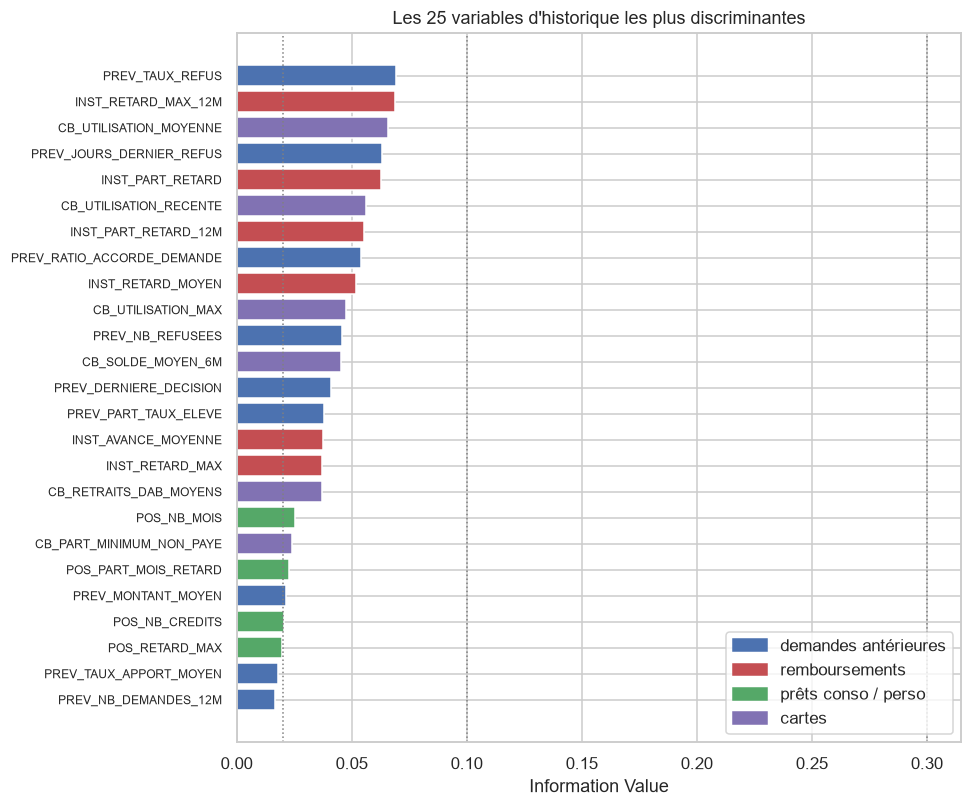

In [13]:
application = pd.read_parquet(DOSSIER_TRAITEES / "application_propre.parquet")
bureau = pd.read_parquet(DOSSIER_TRAITEES / "variables_bureau.parquet")
base = (application.merge(bureau, on="SK_ID_CURR", how="left", validate="one_to_one")
                   .merge(historique, on="SK_ID_CURR", how="left", validate="one_to_one"))
app = base[base["echantillon"] == "apprentissage"].reset_index(drop=True)
y = app["TARGET"]

variables_hist = [c for c in historique.columns if c != "SK_ID_CURR"]
iv_hist = pd.Series(EncodeurWoE(nb_classes=10).fit(app[variables_hist], y).iv_).sort_values(ascending=False)

top = iv_hist.head(25).iloc[::-1]
famille_couleur = {"PREV": "#4C72B0", "INST": "#C44E52", "POS": "#55A868", "CB": "#8172B3"}
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top.index, top.values, color=[famille_couleur[n.split("_")[0]] for n in top.index])
for seuil in (0.02, 0.1, 0.3):
    ax.axvline(seuil, color="grey", ls=":", lw=1)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in famille_couleur.values()],
          labels=["demandes antérieures", "remboursements", "prêts conso / perso", "cartes"], loc="lower right")
ax.set(xlabel="Information Value", title="Les 25 variables d'historique les plus discriminantes")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Lecture.** Aucune variable d'historique n'est forte seule (toutes les IV sont inférieures à 0,1), mais une vingtaine sont utiles, et elles sont **réparties entre les quatre tables** :
- **Demandes antérieures :** le taux de refus passé arrive en tête (0,069), devant le délai depuis le dernier refus et le rapport entre montant accordé et montant demandé. Un client qui a obtenu moins que ce qu'il demandait avait déjà été jugé risqué.
- **Remboursements :** le plus long retard sur les 12 derniers mois (0,069) et la part des échéances payées en retard. Le comportement récent compte autant que l'historique complet.
- **Cartes :** les taux d'utilisation moyen, récent et maximal, ainsi que les retraits d'espèces au distributeur.
- **Prêts à la consommation :** des signaux plus faibles, qui recoupent en partie ceux des remboursements.

# 7. Apport de chaque source d'information

On ajoute les sources une à une à la régression logistique de référence, avec les mêmes plis de validation croisée. On mesure ainsi le gain propre à chaque table.

In [14]:
exclues = ["SK_ID_CURR", "TARGET", "echantillon"] + VARIABLES_EQUITE
qualitatives = [c for c in application.columns if c not in exclues and application[c].dtype.kind not in "biuf"]
numeriques = [c for c in application.columns if c not in exclues and c not in qualitatives]
variables_bureau = [c for c in bureau.columns if c != "SK_ID_CURR"]
familles = {
    "+ bureau de crédit": (variables_bureau, []),
    "+ demandes antérieures": ([c for c in variables_hist if c.startswith("PREV") and c != "PREV_DERNIERE_DECISION"],
                               ["PREV_DERNIERE_DECISION"]),
    "+ remboursements": ([c for c in variables_hist if c.startswith("INST")], []),
    "+ prêts conso / perso": ([c for c in variables_hist if c.startswith("POS")], []),
    "+ cartes de crédit": ([c for c in variables_hist if c.startswith("CB")], []),
}

etapes = [evaluer(pipeline_logistique(numeriques, qualitatives), app[numeriques + qualitatives], y,
                  "Table principale seule")]
num, qual = list(numeriques), list(qualitatives)
for nom, (n, q) in familles.items():
    num, qual = num + n, qual + q
    debut = time.time()
    etapes.append(evaluer(pipeline_logistique(num, qual), app[num + qual], y, nom) | {"variables": len(num) + len(qual)})
    print(f"{nom:<25} AUC = {etapes[-1]['AUC']:.4f}  ({time.time() - debut:.0f} s)")
etapes = pd.DataFrame(etapes).set_index("modèle")
etapes["gain AUC"] = etapes["AUC"].diff()
etapes.round(4)

+ bureau de crédit        AUC = 0.7525  (81 s)
+ demandes antérieures    AUC = 0.7586  (94 s)
+ remboursements          AUC = 0.7643  (107 s)
+ prêts conso / perso     AUC = 0.7687  (110 s)
+ cartes de crédit        AUC = 0.7716  (120 s)


,AUC,écart-type AUC,Gini,AUC PR,Brier,variables,gain AUC
modèle,,,,,,,
Table principale seule,0.7471,0.0012,0.4941,0.2271,0.0686,NaN,NaN
+ bureau de crédit,0.7525,0.0016,0.5049,0.2350,0.0682,105.0,0.0054
+ demandes antérieures,0.7586,0.0014,0.5171,0.2435,0.0678,122.0,0.0061
+ remboursements,0.7643,0.0016,0.5287,0.2483,0.0675,135.0,0.0058
+ prêts conso / perso,0.7687,0.0015,0.5374,0.2535,0.0672,142.0,0.0044
+ cartes de crédit,0.7716,0.0013,0.5431,0.2576,0.0670,152.0,0.0028


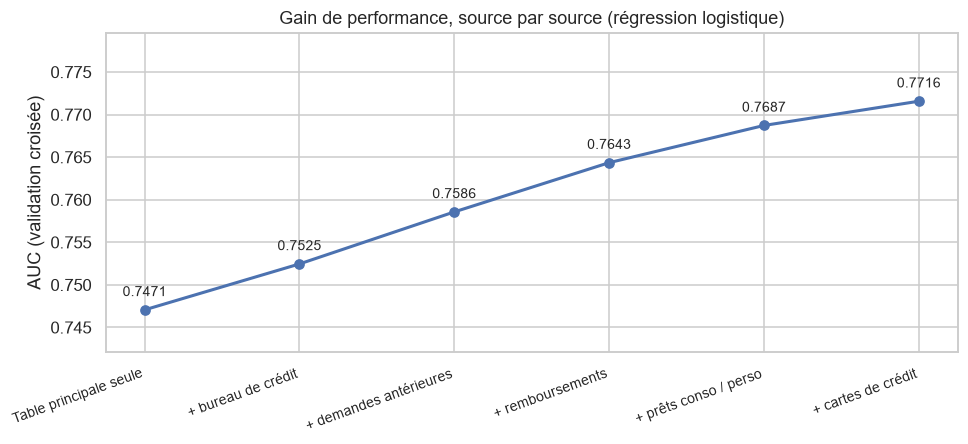

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(range(len(etapes)), etapes["AUC"], marker="o", color="#4C72B0", lw=2)
for i, (nom, ligne) in enumerate(etapes.iterrows()):
    ax.annotate(f"{ligne['AUC']:.4f}", (i, ligne["AUC"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xticks(range(len(etapes)))
ax.set_xticklabels(etapes.index, rotation=20, ha="right", fontsize=9)
ax.set(ylabel="AUC (validation croisée)", title="Gain de performance, source par source (régression logistique)")
ax.set_ylim(etapes["AUC"].min() - 0.005, etapes["AUC"].max() + 0.008)
plt.tight_layout()
plt.show()

**Lecture.** Chaque source améliore le modèle, et les gains s'additionnent :

| Étape | AUC | Gain |
|---|---|---|
| Table principale | 0,7471 | — |
| + bureau de crédit | 0,7525 | +0,0054 |
| + demandes antérieures | 0,7586 | +0,0061 |
| + remboursements | 0,7643 | +0,0058 |
| + prêts conso / perso | 0,7687 | +0,0044 |
| + cartes de crédit | 0,7716 | +0,0028 |

Au total, l'AUC gagne **2,5 points** (de 0,747 à 0,772), et le Gini passe de 0,49 à 0,54. L'AUC précision-rappel, plus sensible à la classe rare, progresse de 0,227 à 0,258, et le score de Brier baisse régulièrement. **L'historique propre à Home Credit apporte trois fois plus que le bureau de crédit externe** (+1,9 point contre +0,5) : un client qui revient, la banque le connaît mieux que n'importe quel organisme extérieur. Les cartes apportent le gain le plus faible, car seul un client sur trois en possède une.

Toutes ces améliorations sont mesurées avec le même modèle linéaire. Le notebook 05 testera un modèle capable de capter des relations non linéaires et des interactions entre ces 152 variables.